# Exact relations and conditional approximations

Quantitatively validate the analytical interpretation of parameter correlations, including the rare solutions for which singlet dominance changes eigenstate.

**Data:** the frozen 3000-run production set (`data/raw`). **Acceptance:** all five normalized residual magnitudes strictly below one. These are *numerical widths*, not independently measured Gaussian standard deviations.

> Start from the repository root or its `notebooks/` folder. No recomputation of the 3000 DE optimizations is required.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works in Jupyter, VS Code, and Colab if the repository is cloned locally.
workdir = Path.cwd().resolve()
candidates = [workdir, workdir.parent]
ROOT = next((p for p in candidates if (p / "data/raw/runs.csv").is_file()
             and (p / "src/model.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find the repository root. Open the project folder (with data/ and src/) "
        "or clone the repository in the Colab session before running the notebook."
    )
sys.path.insert(0, str(ROOT / "src"))
from model import PARAMETERS, V_EW, MASS_WIDTHS, mass_matrix, spectrum
raw = pd.read_csv(ROOT / "data/raw/runs.csv")
print(f"Repository: {ROOT.name}; records: {len(raw):,}; v = {V_EW} GeV")

Repository: DE_Particle_paper_public; records: 3,000; v = 246.22 GeV


In [2]:
residual_cols = ["z_H1", "z_H2", "z_H3", "z_charged", "z_kappa"]
z_abs = np.abs(raw[residual_cols].to_numpy(float))
mask_mass = (z_abs[:, :3] < 1).all(axis=1)
mask_charged = z_abs[:, 3] < 1
mask_kappa = z_abs[:, 4] < 1
mask_all = (z_abs < 1).all(axis=1)
accepted = raw.loc[mask_all].copy()
representative = (accepted.sort_values(["target_index", "loss", "restart"])
                  .drop_duplicates("target_index").sort_values("target_index"))
assert len(raw) == 3000 and len(accepted) == 2971 and len(representative) == 1000

## Exact charged-scalar identity\nThe cubic potential gives \(\mu v_\sigma/v_1=-(v_2/\sqrt{2})[2M_{H^\pm}^2/v^2+\lambda_4]\). This is exact for the implemented model, not a mixing approximation.

In [3]:
params=accepted[list(PARAMETERS)].to_numpy(float)
v1=accepted.v_1.to_numpy(float)
v2=np.sqrt(V_EW**2-v1**2)
left=accepted.mu.to_numpy(float)*accepted.v_sigma.to_numpy(float)/v1
right=-v2/np.sqrt(2)*(2*accepted.mc.to_numpy(float)**2/V_EW**2+accepted.lambda_4.to_numpy(float))
print("Charged identity max absolute difference (GeV):",np.max(np.abs(left-right)))
assert np.max(np.abs(left-right))<1e-9

Charged identity max absolute difference (GeV): 2.2026824808563106e-13


## Exact spectral sum rule\nFor a real symmetric mass matrix and orthogonal eigenvectors, \((M_H^2)_{33}=\sum_i m_{H_i}^2 R_{3i}^2\). Combined with the model equation, \((M_H^2)_{33}=2\lambda_\sigma v_\sigma^2-\mu v_1 v_2/(\sqrt{2}v_\sigma)\). No dominance approximation is needed for these identities.

In [4]:
M2=np.array([mass_matrix(x) for x in params])
eig,R=np.linalg.eigh(M2)
M33=M2[:,2,2]
exact=(eig*R[:,2,:]**2).sum(axis=1)
model_33=(2*accepted.lambda_sigma.to_numpy() * accepted.v_sigma.to_numpy()**2
          - accepted.mu.to_numpy()*v1*v2/(np.sqrt(2)*accepted.v_sigma.to_numpy()))
print("Max error spectral identity (GeV²):",np.max(np.abs(exact-M33)))
print("Max error scalar potential identity (GeV²):",np.max(np.abs(model_33-M33)))
assert np.allclose(exact,M33,rtol=0,atol=1e-8)

Max error spectral identity (GeV²): 5.093170329928398e-11
Max error scalar potential identity (GeV²): 3.637978807091713e-12


## When is the H3 singlet approximation accurate?\nThe simpler statement \(2\lambda_\sigma v_\sigma^2\approx m_{H_3}^2\) is **conditional**, not universal. Quantify the error against the actual singlet fraction \(|R_{33}|^2\).

H3 singlet > 90%: 2882 / 2971 accepted
95th percentile relative error on H3-singlet branch: 1.135%
Largest error among all accepted: 60.41%


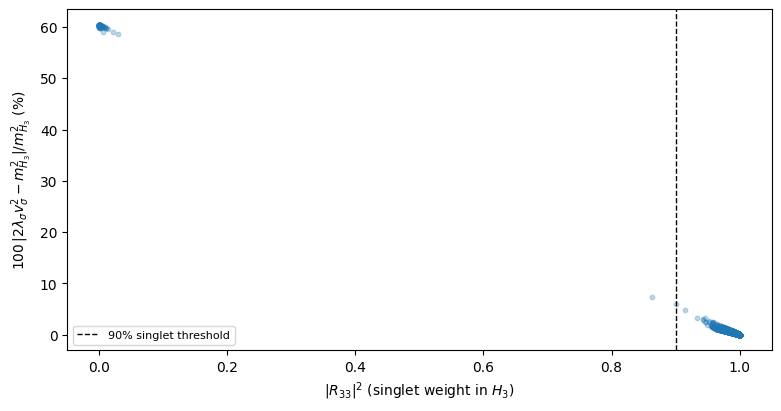

In [5]:
singlet_fraction_H3=R[:,2,2]**2
approx3=2*accepted.lambda_sigma.to_numpy()*accepted.v_sigma.to_numpy()**2
relative_error=np.abs(approx3-eig[:,2])/eig[:,2]
branch=singlet_fraction_H3>0.9
print(f"H3 singlet > 90%: {branch.sum()} / {len(branch)} accepted")
print(f"95th percentile relative error on H3-singlet branch: {100*np.quantile(relative_error[branch],.95):.3f}%")
print(f"Largest error among all accepted: {100*relative_error.max():.2f}%")
fig,ax=plt.subplots(figsize=(7.7,4),layout="constrained")
ax.scatter(singlet_fraction_H3,100*relative_error,s=10,alpha=.28)
ax.axvline(.9,ls='--',c='black',lw=1,label='90% singlet threshold')
ax.set_xlabel(r'$|R_{33}|^2$ (singlet weight in $H_3$)')
ax.set_ylabel(r'$100\,|2\lambda_\sigma v_\sigma^2-m_{H_3}^2|/m_{H_3}^2$ (%)')
ax.legend(fontsize=8)
plt.show()

## Spearman rank correlations (reported separately)\nA high rank correlation does not validate the foregoing approximation globally. The spectral identity is exact; the approximation requires eigenstate-composition information.

In [6]:
for name,df in [('one accepted run per target',representative),('all accepted restarts',accepted)]:
    print(name,': rho(lambda_sigma,v_sigma)=',round(df.lambda_sigma.corr(df.v_sigma,method="spearman"),6),
          '; rho(v_1,mu)=',round(df.v_1.corr(df.mu,method="spearman"),6))

one accepted run per target : rho(lambda_sigma,v_sigma)= -0.997694 ; rho(v_1,mu)= -0.947647
all accepted restarts : rho(lambda_sigma,v_sigma)= -0.962072 ; rho(v_1,mu)= -0.817558
